# Disease Outbreak Prediction System
**Management Science Group Project — 2025/2026**  
Adekunle Ajasin University, Akungba-Akoko

| | |
|---|---|
| **Dataset** | WHO Disease Outbreak News (DONs) via Humanitarian Data Exchange (HDX) |
| **Source** | https://data.humdata.org |
| **Models** | Logistic Regression, Random Forest, XGBoost |
| **Target** | Binary classification — outbreak_occurred (1 = Yes, 0 = No) |

## Cell 1 — Mount Drive and Load Dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

# Load the cleaned dataset from Google Drive
# Update the folder name if yours is different
df = pd.read_csv('/content/drive/MyDrive/Project: Disease Prediction/disease_outbreak_CLEANED.csv')

print('Dataset loaded successfully.')
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print()
print(df.head())
print()
print('Total missing values:', df.isnull().sum().sum())
print('Class distribution:', df['outbreak_occurred'].value_counts().to_dict())

Mounted at /content/drive
Dataset loaded successfully.
Shape: (7316, 12)
Columns: ['Country', 'iso2', 'iso3', 'Year', 'unsd_region', 'unsd_subregion', 'who_region', 'country_total_outbreaks', 'country_outbreak_rate', 'region_outbreaks_that_year', 'global_outbreaks_that_year', 'outbreak_occurred']

       Country iso2 iso3  Year unsd_region unsd_subregion  \
0  Afghanistan   AF  AFG  1996        Asia  Southern Asia   
1  Afghanistan   AF  AFG  1997        Asia  Southern Asia   
2  Afghanistan   AF  AFG  1998        Asia  Southern Asia   
3  Afghanistan   AF  AFG  1999        Asia  Southern Asia   
4  Afghanistan   AF  AFG  2000        Asia  Southern Asia   

                     who_region  country_total_outbreaks  \
0  Eastern Mediterranean Region                       27   
1  Eastern Mediterranean Region                       27   
2  Eastern Mediterranean Region                       27   
3  Eastern Mediterranean Region                       27   
4  Eastern Mediterranean Region   

## Cell 1.5 — Feature Engineering: Lag Features
These three temporal features give the model a sense of history.  
Without them, the model treats every year independently and misses the pattern that countries with recent outbreaks tend to have more.

In [2]:
# Sort before creating lag features - order matters here
df = df.sort_values(['Country', 'Year']).reset_index(drop=True)

# Feature 1: Did this country have an outbreak the year before?
df['prev_year_outbreak'] = (
    df.groupby('Country')['outbreak_occurred']
    .shift(1)
    .fillna(0)
    .astype(int)
)

# Feature 2: How many of the past 3 years had outbreaks in this country?
df['outbreaks_last_3_years'] = (
    df.groupby('Country')['outbreak_occurred']
    .transform(lambda x: x.shift(1).rolling(3, min_periods=1).sum())
    .fillna(0)
    .astype(int)
)

# Feature 3: How many years in a row has this country had outbreaks?
def consecutive_streak(series):
    streak = []
    count = 0
    for val in series:
        if val == 1:
            count += 1
        else:
            count = 0
        streak.append(count)
    # Shift by 1 so only past data is used, not the current year
    return pd.Series(streak, index=series.index).shift(1).fillna(0.0).astype(int)

df['consecutive_outbreak_years'] = (
    df.groupby('Country')['outbreak_occurred']
    .transform(consecutive_streak)
)

print('Lag features added. Verification sample:')
print(df[['Country', 'Year', 'outbreak_occurred',
          'prev_year_outbreak', 'outbreaks_last_3_years',
          'consecutive_outbreak_years']].head(10).to_string(index=False))
print()
print('Total columns:', df.shape[1])

Lag features added. Verification sample:
    Country  Year  outbreak_occurred  prev_year_outbreak  outbreaks_last_3_years  consecutive_outbreak_years
Afghanistan  1996                  0                   0                       0                           0
Afghanistan  1997                  0                   0                       0                           0
Afghanistan  1998                  1                   0                       0                           0
Afghanistan  1999                  1                   1                       1                           1
Afghanistan  2000                  1                   1                       2                           2
Afghanistan  2001                  1                   1                       3                           3
Afghanistan  2002                  1                   1                       3                           4
Afghanistan  2003                  1                   1                       3       

## Cell 2 — Encode Categorical Columns
Machine learning models only work with numbers.  
LabelEncoder converts text columns like Country and Region into integers.

In [3]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Separate features from target variable
# iso2 and iso3 are dropped - Country already captures country identity
X = df.drop(columns=['outbreak_occurred', 'iso2', 'iso3'])
y = df['outbreak_occurred']

le = LabelEncoder()
cat_cols = ['Country', 'unsd_region', 'unsd_subregion', 'who_region']

for col in cat_cols:
    X[col] = le.fit_transform(X[col].astype(str))

print('Encoding complete. Column types:')
print(X.dtypes)
print()
print('Sample after encoding:')
print(X.head())

Encoding complete. Column types:
Country                         int64
Year                            int64
unsd_region                     int64
unsd_subregion                  int64
who_region                      int64
country_total_outbreaks         int64
country_outbreak_rate         float64
region_outbreaks_that_year    float64
global_outbreaks_that_year      int64
prev_year_outbreak              int64
outbreaks_last_3_years          int64
consecutive_outbreak_years      int64
dtype: object

Sample after encoding:
   Country  Year  unsd_region  unsd_subregion  who_region  \
0        0  1996            2              12           1   
1        0  1997            2              12           1   
2        0  1998            2              12           1   
3        0  1999            2              12           1   
4        0  2000            2              12           1   

   country_total_outbreaks  country_outbreak_rate  region_outbreaks_that_year  \
0                       2

## Cell 3 — Scale Features and Split Data
StandardScaler brings all numeric columns to the same range (mean=0, std=1).  
stratify=y keeps the class ratio consistent in both train and test sets.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training set size:', X_train.shape)
print('Testing set size: ', X_test.shape)
print()
print('Class distribution in training set:')
print(dict(zip(*np.unique(y_train, return_counts=True))))

Training set size: (5852, 12)
Testing set size:  (1464, 12)

Class distribution in training set:
{np.int64(0): np.int64(3856), np.int64(1): np.int64(1996)}


## Cell 4 — Handle Class Imbalance with SMOTE
The dataset has more No Outbreak rows than Outbreak rows.  
SMOTE generates synthetic minority class samples to balance the training set.  
Important: SMOTE is applied to training data only, never to the test set.

In [5]:
!pip install imbalanced-learn -q

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print('After SMOTE - class distribution:')
print(dict(zip(*np.unique(y_train, return_counts=True))))
print('New training set size:', X_train.shape)

After SMOTE - class distribution:
{np.int64(0): np.int64(3856), np.int64(1): np.int64(3856)}
New training set size: (7712, 12)


## Cell 5 — Model 1: Logistic Regression (Baseline)
The simplest model. Included as a baseline to show that the more complex  
models are genuinely learning better patterns, not just benefiting from luck.

In [6]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print('Logistic Regression training complete.')

Logistic Regression training complete.


## Cell 6 — Model 2: Random Forest
An ensemble method that builds 100 decision trees and combines their votes.  
More powerful than Logistic Regression and handles non-linear patterns well.  
Also provides feature importance scores used in the analysis.

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print('Random Forest training complete.')

Random Forest training complete.


## Cell 7 — Model 3: XGBoost
Gradient boosting model — builds trees sequentially, each one correcting  
the errors of the previous. Generally the strongest performer on  
structured tabular data and handles class imbalance better than the others.

In [8]:
!pip install xgboost -q

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    eval_metric='logloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

print('XGBoost training complete.')

XGBoost training complete.


## Cell 8 — Model Comparison Table
All three models are evaluated on the same test set.  
F1-Score is the primary metric because it balances precision and recall,  
which matters most in health prediction where missing an outbreak is costly.

In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

models = {
    'Logistic Regression': lr_preds,
    'Random Forest':       rf_preds,
    'XGBoost':             xgb_preds
}

print(f"{'Model':<25} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1-Score':>10}")
print('-' * 65)

for name, preds in models.items():
    acc  = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec  = recall_score(y_test, preds, zero_division=0)
    f1   = f1_score(y_test, preds, zero_division=0)
    print(f"{name:<25} {acc:>10.2%} {prec:>10.2%} {rec:>10.2%} {f1:>10.2%}")

Model                       Accuracy  Precision     Recall   F1-Score
-----------------------------------------------------------------
Logistic Regression           86.27%     79.92%     79.76%     79.84%
Random Forest                 87.09%     81.89%     79.76%     80.81%
XGBoost                       87.23%     82.50%     79.36%     80.90%


## Cell 9 — Confusion Matrix (XGBoost)
Shows a breakdown of correct and incorrect predictions for XGBoost.  
Top-left: correctly predicted No Outbreak  
Bottom-right: correctly predicted Outbreak  
Off-diagonal values are the errors.

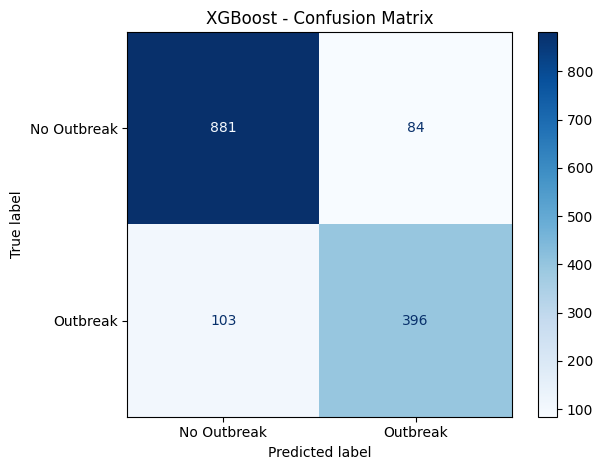

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, xgb_preds)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Outbreak', 'Outbreak']
)
disp.plot(cmap='Blues')
plt.title('XGBoost - Confusion Matrix')
plt.tight_layout()
plt.show()

## Cell 10 — Feature Importance (Random Forest)
Shows which features contributed most to the Random Forest predictions.  
Higher bars mean the model relied on that feature more when making decisions.  
Useful for explaining the model's reasoning in the project report.

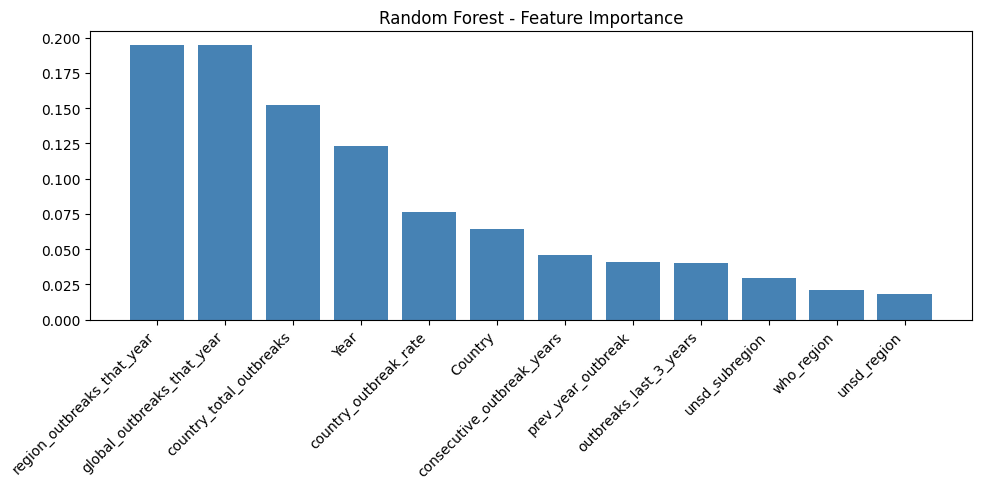

In [11]:
import matplotlib.pyplot as plt

feature_names = [c for c in df.columns
                 if c not in ['outbreak_occurred', 'iso2', 'iso3']]

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.bar(range(len(feature_names)), importances[indices], color='steelblue')
plt.xticks(
    range(len(feature_names)),
    [feature_names[i] for i in indices],
    rotation=45, ha='right'
)
plt.title('Random Forest - Feature Importance')
plt.tight_layout()
plt.show()

## Cell 11 — Install Folium

In [12]:
!pip install folium requests -q

print('Folium installed.')

Folium installed.


## Cell 12 — Build 2026 Risk Prediction Table
Uses the trained XGBoost model to predict outbreak probability for every  
country in 2026. predict_proba gives a probability between 0 and 1,  
which is more informative than a simple Yes/No prediction.  
Countries are then grouped into Low, Medium, or High risk.

In [13]:
df_2026 = df[df['Year'] == 2026].copy().reset_index(drop=True)

X_map = df_2026.drop(columns=['outbreak_occurred', 'iso2', 'iso3'])
le_map = LabelEncoder()
cat_cols = ['Country', 'unsd_region', 'unsd_subregion', 'who_region']
for col in cat_cols:
    X_map[col] = le_map.fit_transform(X_map[col].astype(str))

scaler_map = StandardScaler()
X_map_scaled = scaler_map.fit_transform(X_map)

risk_probs = xgb_model.predict_proba(X_map_scaled)[:, 1]

map_df = df_2026[['Country', 'iso3', 'who_region']].copy()
map_df['risk_score'] = risk_probs

def risk_label(score):
    if score >= 0.6:
        return 'High'
    elif score >= 0.35:
        return 'Medium'
    else:
        return 'Low'

map_df['risk_level'] = map_df['risk_score'].apply(risk_label)

print('Risk level distribution:')
print(map_df['risk_level'].value_counts())
print()
print(map_df.head(10).to_string(index=False))

Risk level distribution:
risk_level
High      188
Low        38
Medium     10
Name: count, dtype: int64

            Country iso3                   who_region  risk_score risk_level
        Afghanistan  AFG Eastern Mediterranean Region    0.910610       High
            Albania  ALB              European Region    0.999704       High
            Algeria  DZA               African Region    0.991968       High
     American Samoa  ASM       Western Pacific Region    0.029749        Low
            Andorra  AND              European Region    0.998126       High
             Angola  AGO               African Region    0.992142       High
           Anguilla  AIA       Region of the Americas    0.510438     Medium
Antigua and Barbuda  ATG       Region of the Americas    0.951960       High
          Argentina  ARG       Region of the Americas    0.996761       High
            Armenia  ARM              European Region    0.999625       High


## Cell 13 — Build and Save the Geographic Risk Map
Folium generates an interactive HTML map.  
The choropleth layer fills each country by risk level (green to red).  
Circle markers on major countries show a popup with full details on click.

In [14]:
import folium

geo_url = 'https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json'

risk_numeric = {'Low': 1, 'Medium': 2, 'High': 3}
map_df['risk_numeric'] = map_df['risk_level'].map(risk_numeric)

m = folium.Map(location=[20, 0], zoom_start=2, tiles='OpenStreetMap')

folium.Choropleth(
    geo_data=geo_url,
    name='Disease Outbreak Risk',
    data=map_df,
    columns=['Country', 'risk_numeric'],
    key_on='feature.properties.name',
    fill_color='RdYlGn_r',
    fill_opacity=0.75,
    line_opacity=0.2,
    legend_name='Outbreak Risk Level  (1 = Low    2 = Medium    3 = High)',
    nan_fill_color='lightgrey'
).add_to(m)

country_coords = {
    'Afghanistan': [33.9, 67.7], 'Albania': [41.2, 20.2],
    'Algeria': [28.0, 1.7], 'Angola': [-11.2, 17.9],
    'Argentina': [-38.4, -63.6], 'Armenia': [40.1, 45.0],
    'Australia': [-25.3, 133.8], 'Bangladesh': [23.7, 90.4],
    'Brazil': [-14.2, -51.9], 'Cameroon': [3.9, 11.5],
    'Canada': [56.1, -106.3], 'China': [35.9, 104.2],
    'Colombia': [4.6, -74.3], 'Congo': [-0.2, 15.8],
    'Democratic Republic of the Congo': [-4.0, 21.8],
    'Egypt': [26.8, 30.8], 'Ethiopia': [9.1, 40.5],
    'France': [46.2, 2.2], 'Germany': [51.2, 10.5],
    'Ghana': [7.9, -1.0], 'India': [20.6, 79.0],
    'Indonesia': [-0.8, 113.9], 'Iran': [32.4, 53.7],
    'Iraq': [33.2, 43.7], 'Italy': [41.9, 12.6],
    'Japan': [36.2, 138.3], 'Kenya': [-0.0, 37.9],
    'Libya': [26.3, 17.2], 'Madagascar': [-18.8, 46.9],
    'Malaysia': [4.2, 108.0], 'Mali': [17.6, -2.0],
    'Mexico': [23.6, -102.6], 'Morocco': [31.8, -7.1],
    'Mozambique': [-18.7, 35.5], 'Myanmar': [17.1, 96.0],
    'Nigeria': [9.1, 8.7], 'Pakistan': [30.4, 69.3],
    'Peru': [-9.2, -75.0], 'Philippines': [12.9, 121.8],
    'Russia': [61.5, 105.3], 'Saudi Arabia': [23.9, 45.1],
    'Somalia': [5.2, 46.2], 'South Africa': [-30.6, 22.9],
    'South Sudan': [6.9, 31.3], 'Sudan': [12.9, 30.2],
    'Syria': [34.8, 38.9], 'Tanzania': [-6.4, 34.9],
    'Thailand': [15.9, 100.9], 'Turkey': [38.9, 35.2],
    'Uganda': [1.4, 32.3], 'Ukraine': [48.4, 31.2],
    'United Kingdom': [55.4, -3.4],
    'United States of America': [37.1, -95.7],
    'Venezuela': [6.4, -66.6], 'Vietnam': [14.1, 108.3],
    'Yemen': [15.6, 48.5], 'Zambia': [-13.1, 27.8],
    'Zimbabwe': [-19.0, 29.2]
}

color_map = {'Low': 'green', 'Medium': 'orange', 'High': 'red'}

for _, row in map_df.iterrows():
    coords = country_coords.get(row['Country'])
    if coords:
        folium.CircleMarker(
            location=coords,
            radius=6,
            color=color_map[row['risk_level']],
            fill=True,
            fill_opacity=0.8,
            popup=folium.Popup(
                f"<b>{row['Country']}</b><br>"
                f"Risk Level: {row['risk_level']}<br>"
                f"Risk Score: {row['risk_score']:.2%}<br>"
                f"WHO Region: {row['who_region']}",
                max_width=200
            ),
            tooltip=f"{row['Country']} — {row['risk_level']} Risk"
        ).add_to(m)

folium.LayerControl().add_to(m)
m.save('outbreak_risk_map_2026.html')

print('Map saved as outbreak_risk_map_2026.html')
print('Countries with markers:', sum(1 for c in map_df['Country'] if c in country_coords))
print('Total countries in choropleth:', len(map_df))

Map saved as outbreak_risk_map_2026.html
Countries with markers: 50
Total countries in choropleth: 236


## Cell 14 — Display Map Inline
Renders the map inside the Colab notebook.  
To save it: open the Files panel on the left sidebar,  
right-click outbreak_risk_map_2026.html and select Download.

In [15]:
from IPython.display import IFrame, display

display(IFrame('outbreak_risk_map_2026.html', width=900, height=500))

print('Map loaded. Click any marker to see country details.')
print('To download: Files panel (left sidebar) -> right-click outbreak_risk_map_2026.html -> Download')

Map loaded. Click any marker to see country details.
To download: Files panel (left sidebar) -> right-click outbreak_risk_map_2026.html -> Download
